In [1]:
%pip install -q onnx onnxruntime

Note: you may need to restart the kernel to use updated packages.


In [2]:
import copy
import json
import math
import random
import re
import tarfile
import time
import urllib.request
import warnings
import zipfile
from collections import deque
from dataclasses import dataclass
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from IPython.display import display
from scipy import ndimage
from scipy.io import loadmat
from sklearn.metrics import average_precision_score, roc_auc_score
from torch.optim.lr_scheduler import CosineAnnealingLR

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

INPUT_ROOT = Path("/kaggle/input")
WORK_DIR = Path("/kaggle/working")
RESULTS_DIR = WORK_DIR / "results"
FIGURES_DIR = WORK_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

PED2_URL = "http://www.svcl.ucsd.edu/projects/anomaly/UCSD_Anomaly_Dataset.tar.gz"
AVENUE_URLS = (
    "https://www.cse.cuhk.edu.hk/~leojia/projects/detectabnormal/Avenue_Dataset.zip",
    "https://www.cse.cuhk.edu.hk/~leojia/projects/detectabnormal/ground_truth_demo.zip",
)

QUICK_RUN = False
RUN_AVENUE = True

PED2_IMAGE_SIZE = (192, 288)
AVENUE_IMAGE_SIZE = (144, 256)  # smaller so avenue features fit in ram
PIXEL_EVAL_SIZE = (120, 180)

CONTEXT_LENGTH = 8
HORIZON = 1
EVAL_START = 12
TOP_FRACTION = 0.01 
FUSION_ALPHA = 0.5  
THRESHOLD_PERCENTILES = (95.0, 97.5, 99.0)

HIDDEN_CHANNELS = 64
LSTM_LAYERS = 2
BATCH_SIZE = 16
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

SEEDS = [0] if QUICK_RUN else [0, 1, 2, 3, 4]
ABLATION_SEEDS = SEEDS[:3]
PED2_EPOCHS = 5 if QUICK_RUN else 30
AVENUE_EPOCHS = 2 if QUICK_RUN else 8
CONTEXT_ABLATION = (1, 4, 8, 12)
HORIZON_ABLATION = (2, 4)
BOOTSTRAP_SAMPLES = 300 if QUICK_RUN else 2000
SPLIT_SEED = 2026
PED2_VALIDATION_VIDEOS = 4
AVENUE_VALIDATION_VIDEOS = 3


assert EVAL_START >= max(
    max(CONTEXT_ABLATION), CONTEXT_LENGTH + max(HORIZON_ABLATION) - 1
)
pd.set_option("display.float_format", "{:.4g}".format)


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


gpu_name = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "no GPU"
print(f"device: {DEVICE} ({gpu_name}), torch {torch.__version__}")

device: cuda (Tesla T4), torch 2.11.0+cu130


In [3]:
@dataclass
class Video:
    name: str
    frames: np.ndarray
    labels: np.ndarray = None
    masks: np.ndarray = None


IMAGE_SUFFIXES = {".tif", ".tiff", ".bmp", ".png", ".jpg", ".jpeg"}


def list_images(folder):
    return sorted(
        p
        for p in folder.iterdir()
        if p.suffix.lower() in IMAGE_SUFFIXES and not p.name.startswith(".")
    )


def read_gray_sequence(folder):
    return np.stack(
        [cv2.imread(str(p), cv2.IMREAD_GRAYSCALE) for p in list_images(folder)]
    )


def to_rgb(gray_frames):
    return np.repeat(gray_frames[..., None], 3, axis=-1)


def find_ped2_root(search_root):
    candidates = [
        p
        for p in search_root.rglob("UCSDped2")
        if p.is_dir() and (p / "Train").is_dir() and (p / "Test").is_dir()
    ]
    return sorted(candidates)[0] if candidates else None


def fetch_archive(url, target):
    target.mkdir(parents=True, exist_ok=True)
    archive = target / url.rsplit("/", 1)[-1]
    urllib.request.urlretrieve(url, archive)
    if archive.suffix == ".zip":
        with zipfile.ZipFile(archive) as zf:
            zf.extractall(target)
    else:
        with tarfile.open(archive) as tar:
            try:
                tar.extractall(target, filter="data")
            except TypeError:
                tar.extractall(target)
    archive.unlink()


def locate_ped2():
    root = find_ped2_root(INPUT_ROOT) if INPUT_ROOT.exists() else None
    if root is not None:
        return root
    target = WORK_DIR / "ucsd"
    root = find_ped2_root(target) if target.exists() else None
    if root is not None:
        return root
    print("ped2 not in input, downloading from ucsd site.. takes few mins")
    fetch_archive(PED2_URL, target)
    return find_ped2_root(target)


def parse_ucsd_frame_labels(m_file):
    text = m_file.read_text(errors="ignore")
    ranges = {}
    for index, body in re.findall(r"gt\{(\d+)\}\s*=\s*\[([^\]]*)\]", text):
        ranges[int(index)] = [
            (int(a), int(b)) for a, b in re.findall(r"(\d+)\s*:\s*(\d+)", body)
        ]
    return ranges


def load_ped2(root):
    train = [
        Video(folder.name, to_rgb(read_gray_sequence(folder)))
        for folder in sorted((root / "Train").iterdir())
        if folder.is_dir() and re.fullmatch(r"Train\d+", folder.name)
    ]
    m_files = sorted(root.rglob("*.m"))
    label_ranges = parse_ucsd_frame_labels(m_files[0]) if m_files else {}

    test = []
    for folder in sorted((root / "Test").iterdir()):
        if not (folder.is_dir() and re.fullmatch(r"Test\d+", folder.name)):
            continue
        frames = read_gray_sequence(folder)
        mask_folder = folder.with_name(folder.name + "_gt")
        masks = read_gray_sequence(mask_folder) > 0 if mask_folder.is_dir() else None
        if masks is not None and len(masks) != len(frames):
            print(
                f"{folder.name} has {len(frames)} frames but {len(masks)} masks, skipping masks"
            )
            masks = None

        index = int(folder.name[4:])
        if index in label_ranges:
            labels = np.zeros(len(frames), dtype=np.int64)
            for first, last in label_ranges[index]:
                labels[first - 1 : last] = 1  
        elif masks is not None:
            labels = masks.reshape(len(masks), -1).any(axis=1).astype(np.int64)
        else:
            raise FileNotFoundError(f"no labels or masks for {folder.name}")
        test.append(Video(folder.name, to_rgb(frames), labels, masks))
    return train, test



def split_videos(videos, holdout_count, seed):
    rng = np.random.default_rng(seed)
    held_out = set(rng.choice(len(videos), holdout_count, replace=False).tolist())
    kept = [v for i, v in enumerate(videos) if i not in held_out]
    held = [v for i, v in enumerate(videos) if i in held_out]
    return kept, held


ped2_root = locate_ped2()
ped2_train_all, ped2_test = load_ped2(ped2_root)
ped2_train, ped2_val = split_videos(ped2_train_all, PED2_VALIDATION_VIDEOS, SPLIT_SEED)
ped2_splits = {"train": ped2_train, "val": ped2_val, "test": ped2_test}

test_frames = sum(len(v.labels) for v in ped2_test)
anomalous_frames = sum(int(v.labels.sum()) for v in ped2_test)
print(f"ped2 at {ped2_root}")
print(f"train {len(ped2_train)}, val {len(ped2_val)}, test {len(ped2_test)} videos")
print("val videos:", ", ".join(v.name for v in ped2_val))
print(f"test frames: {test_frames} ({anomalous_frames} anomalous)")
print(f"got pixel masks for {sum(v.masks is not None for v in ped2_test)} test videos")

ped2 at /kaggle/input/datasets/srinairs/ucsdped2/UCSD_Anomaly_Dataset.v1p2/UCSDped2
train 12, val 4, test 12 videos
val videos: Train001, Train003, Train011, Train012
test frames: 2010 (1648 anomalous)
got pixel masks for 12 test videos


In [4]:
class FeatureExtractor(nn.Module):

    def __init__(self, pretrained=True):
        super().__init__()
        weights = (
            torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        )
        backbone = torchvision.models.resnet18(weights=weights)
        self.stem = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
            backbone.layer1,
        )
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.register_buffer(
            "mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )
        self.register_buffer(
            "std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )
        self.eval().requires_grad_(False)

    def forward(self, images):
        x = (images.permute(0, 3, 1, 2).float() / 255.0 - self.mean) / self.std
        middle = self.layer2(self.stem(x))
        return middle, self.layer3(middle)


def resize_frames(frames, image_size):
    height, width = image_size
    if frames.shape[1:3] == (height, width):
        return frames
    return np.stack(
        [cv2.resize(f, (width, height), interpolation=cv2.INTER_AREA) for f in frames]
    )


@torch.no_grad()
def extract_features(extractor, videos, image_size, batch_size=64):
    features = {}
    for video in videos:
        middles, deeps = [], []
        for start in range(0, len(video.frames), batch_size):
            batch = resize_frames(video.frames[start : start + batch_size], image_size)
            with torch.autocast(DEVICE.type, enabled=USE_AMP):
                middle, deep = extractor(torch.from_numpy(batch).to(DEVICE))
            middles.append(middle.half().cpu())
            deeps.append(deep.half().cpu())
        features[video.name] = (torch.cat(middles), torch.cat(deeps))
    return features


@dataclass
class ChannelStats:
    mean: torch.Tensor
    std: torch.Tensor


def channel_statistics(features, videos):
    total, total_sq, count = 0.0, 0.0, 0
    for video in videos:
        x = features[video.name][0].float()
        total = total + x.sum(dim=(0, 2, 3))
        total_sq = total_sq + x.pow(2).sum(dim=(0, 2, 3))
        count += x.numel() // x.shape[1]
    mean = total / count
    std = (total_sq / count - mean.pow(2)).clamp_min(0).sqrt()
    std = std.clamp_min(
        0.1 * std.median()
    ) 
    return ChannelStats(mean.view(1, -1, 1, 1), std.view(1, -1, 1, 1))


class FeatureBank:

    def __init__(self, features, videos, stats):
        normalized = [
            ((features[v.name][0].float() - stats.mean) / stats.std).half()
            for v in videos
        ]
        self.names = [v.name for v in videos]
        self.lengths = [len(x) for x in normalized]
        self.offsets = np.cumsum([0] + self.lengths[:-1]).tolist()
        self.data = torch.cat(normalized).to(DEVICE)

    def spans(self):
        return zip(self.names, self.offsets, self.lengths)

    def targets(self, context, horizon):
        first = context + horizon - 1
        return torch.cat(
            [
                torch.arange(offset + first, offset + length)
                for _, offset, length in self.spans()
            ]
        ).to(DEVICE)

    def sequences(self, targets, context, horizon):
        steps = torch.arange(context, device=DEVICE) - (context + horizon - 1)
        return self.data[targets[:, None] + steps], self.data[targets]


extractor = FeatureExtractor().to(DEVICE)
started = time.time()
ped2_features = extract_features(extractor, ped2_train_all + ped2_test, PED2_IMAGE_SIZE)
middle_shape = tuple(next(iter(ped2_features.values()))[0].shape[1:])
deep_shape = tuple(next(iter(ped2_features.values()))[1].shape[1:])
print(
    f"features done for {len(ped2_features)} videos, took {time.time() - started:.0f}s"
)
print(f"layer2 shape {middle_shape}, layer3 shape {deep_shape}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 208MB/s]


features done for 28 videos, took 12s
layer2 shape (128, 24, 36), layer3 shape (256, 12, 18)


In [5]:
@dataclass
class ScoreSet:
    frame: dict
    maps: dict = None


def top_fraction_mean(error_maps, fraction=TOP_FRACTION):
    flat = error_maps.flatten(1)
    # mean of the worst patches, plain max is too noisy
    k = max(1, round(flat.shape[1] * fraction))
    return flat.topk(k, dim=1).values.mean(dim=1)


class ConvLSTMCell(nn.Module):
    def __init__(self, input_channels, hidden_channels, kernel_size=3):
        super().__init__()
        self.gates = nn.Conv2d(
            input_channels + hidden_channels,
            4 * hidden_channels,
            kernel_size,
            padding=kernel_size // 2,
        )

    def forward(self, x, state):
        hidden, cell = state
        input_gate, forget_gate, output_gate, candidate = self.gates(
            torch.cat([x, hidden], dim=1)
        ).chunk(4, dim=1)
        cell = torch.sigmoid(forget_gate) * cell + torch.sigmoid(
            input_gate
        ) * torch.tanh(candidate)
        hidden = torch.sigmoid(output_gate) * torch.tanh(cell)
        return hidden, cell


class FeaturePredictor(nn.Module):

    def __init__(
        self,
        channels=128,
        hidden_channels=HIDDEN_CHANNELS,
        layers=LSTM_LAYERS,
        zero_init_head=True,
    ):
        super().__init__()
        self.hidden_channels = hidden_channels
        self.encoder = nn.Conv2d(channels, hidden_channels, 1)
        self.cells = nn.ModuleList(
            ConvLSTMCell(hidden_channels, hidden_channels) for _ in range(layers)
        )
        self.head = nn.Conv2d(hidden_channels, channels, 1)
        # zero head = untrained model just copies the last map (persistence baseline)
        if zero_init_head:
            nn.init.zeros_(self.head.weight)
            nn.init.zeros_(self.head.bias)

    def forward(self, sequence):
        sequence = sequence.float()
        bsz, n_steps, _, height, width = sequence.shape
        states = []
        for _ in self.cells:
            zeros = sequence.new_zeros(bsz, self.hidden_channels, height, width)
            states.append((zeros, zeros))
        for step in range(n_steps):
            x = self.encoder(sequence[:, step])
            for index, cell in enumerate(self.cells):
                states[index] = cell(x, states[index])
                x = states[index][0]
        return sequence[:, -1] + self.head(x)  # predict a correction on top of last map


class PersistencePredictor(nn.Module):
    def forward(self, sequence):
        return sequence[:, -1].float()


class RandomPredictor(nn.Module):
    def forward(self, sequence):
        return torch.randn_like(sequence[:, -1].float())


@torch.no_grad()
def prediction_loss(model, bank, frame_idx, context, horizon, bsz=128):
    model.eval()
    total = 0.0
    for batch_idx in frame_idx.split(bsz):
        inputs, targets = bank.sequences(batch_idx, context, horizon)
        with torch.autocast(DEVICE.type, enabled=USE_AMP):
            outputs = model(inputs)
        loss = F.mse_loss(outputs.float(), targets.float(), reduction="sum")
        total += loss.item() / targets[0].numel()
    return total / len(frame_idx)


def train(model, bank, frame_idx, context, horizon, optimizer, scaler):
    model.train()
    running = 0.0
    order = frame_idx[torch.randperm(len(frame_idx), device=DEVICE)]
    for batch_idx in order.split(BATCH_SIZE):
        inputs, targets = bank.sequences(batch_idx, context, horizon)
        with torch.autocast(DEVICE.type, enabled=USE_AMP):
            outputs = model(inputs)
        loss = F.mse_loss(outputs.float(), targets.float())
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running += loss.item() * len(batch_idx)
    return running / len(frame_idx)


def train_predictor(train_bank, val_bank, context, horizon, seed, n_epochs):
    seed_everything(seed)
    model = FeaturePredictor(channels=train_bank.data.shape[1]).to(DEVICE)
    optimizer = optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    scheduler = CosineAnnealingLR(optimizer, T_max=n_epochs)
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)
    train_idx = train_bank.targets(context, horizon)
    val_idx = val_bank.targets(context, horizon)

    best_loss, best_state, history = math.inf, None, []
    for epoch in range(1, n_epochs + 1):
        train_loss = train(
            model, train_bank, train_idx, context, horizon, optimizer, scaler
        )
        scheduler.step()
        val_loss = prediction_loss(model, val_bank, val_idx, context, horizon)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history)


def rearrange_history(sequence, mode, generator):
    if mode == "ordered" or sequence.shape[1] == 1:
        return sequence
    batch, steps = sequence.shape[:2]
    rows = torch.arange(batch, device=sequence.device)[:, None]
    if mode == "full_shuffle":
        order = torch.rand(
            batch, steps, generator=generator, device=sequence.device
        ).argsort(dim=1)
        return sequence[rows, order]
    # keep the last frame fixed, moving it shifts the residual anchor and
    # would hurt even a model that ignores temporal order
    history, last = sequence[:, :-1], sequence[:, -1:]
    if mode == "history_shuffle":
        order = torch.rand(
            batch, steps - 1, generator=generator, device=sequence.device
        ).argsort(dim=1)
        history = history[rows, order]
    elif mode == "history_reversed":
        history = history.flip(1)
    elif mode == "static_history":
        history = last.expand_as(history)
    else:
        raise ValueError(f"Unknown history mode: {mode}")
    return torch.cat([history, last], dim=1)


@torch.no_grad()
def predictor_scores(
    model,
    bank,
    context,
    horizon,
    history="ordered",
    keep_maps=False,
    seed=0,
    batch_size=128,
):
    model.eval()
    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    first = context + horizon - 1
    map_shape = tuple(bank.data.shape[-2:])
    frame_scores, maps = {}, {}
    for name, offset, length in bank.spans():
        scores = np.full(length, np.nan, dtype=np.float32)
        video_maps = (
            torch.full((length, *map_shape), float("nan"), dtype=torch.float16)
            if keep_maps
            else None
        )
        if length > first:
            chunk_scores, chunk_maps = [], []
            for batch in torch.arange(
                offset + first, offset + length, device=DEVICE
            ).split(batch_size):
                sequence, target = bank.sequences(batch, context, horizon)
                sequence = rearrange_history(sequence, history, generator)
                with torch.autocast(DEVICE.type, enabled=USE_AMP):
                    prediction = model(sequence)
                error = (prediction.float() - target.float()).pow(2).mean(dim=1)
                chunk_scores.append(top_fraction_mean(error).cpu())
                if keep_maps:
                    chunk_maps.append(error.half().cpu())
            scores[first:] = torch.cat(chunk_scores).numpy()
            if keep_maps:
                video_maps[first:] = torch.cat(chunk_maps)
        frame_scores[name] = scores
        if keep_maps:
            maps[name] = video_maps
    return ScoreSet(frame_scores, maps if keep_maps else None)


def patch_embeddings(middle, deep):
    deep = F.interpolate(
        deep, size=middle.shape[-2:], mode="bilinear", align_corners=False
    )
    return F.avg_pool2d(
        torch.cat([middle, deep], dim=1),
        3,
        stride=1,
        padding=1,
        count_include_pad=False,
    )


@torch.no_grad()
def greedy_coreset(embeddings, ratio, projection_dim, seed):
    generator = torch.Generator(device=embeddings.device).manual_seed(seed)
    projection = torch.randn(
        embeddings.shape[1],
        projection_dim,
        generator=generator,
        device=embeddings.device,
    )
    reduced = torch.cat(
        [chunk.float() @ projection for chunk in embeddings.split(65536)]
    ) / math.sqrt(projection_dim)
    count = max(1, int(len(reduced) * ratio))
    selected = torch.empty(count, dtype=torch.long, device=embeddings.device)
    current = torch.randint(
        len(reduced), (), generator=generator, device=embeddings.device
    )
    min_distance = torch.full((len(reduced),), float("inf"), device=embeddings.device)
    for index in range(count):
        selected[index] = current
        min_distance = torch.minimum(
            min_distance, (reduced - reduced[current]).pow(2).sum(dim=1)
        )
        current = torch.argmax(min_distance)
    return selected


class PatchCore:

    def __init__(
        self,
        coreset_ratio=0.05,
        frame_stride=2,
        projection_dim=128,
        seed=0,
        batch_size=32,
    ):
        self.coreset_ratio = coreset_ratio
        self.frame_stride = frame_stride
        self.projection_dim = projection_dim
        self.seed = seed
        self.batch_size = batch_size

    def embed(self, middle, deep):
        return patch_embeddings(middle.to(DEVICE).float(), deep.to(DEVICE).float())

    @torch.no_grad()
    def fit(self, features, videos):
        chunks = []
        for video in videos:
            middle, deep = features[video.name]
            middle, deep = middle[:: self.frame_stride], deep[:: self.frame_stride]
            for start in range(0, len(middle), self.batch_size):
                embedding = self.embed(
                    middle[start : start + self.batch_size],
                    deep[start : start + self.batch_size],
                )
                chunks.append(
                    embedding.permute(0, 2, 3, 1).reshape(-1, embedding.shape[1]).half()
                )
        bank = torch.cat(chunks)
        selected = greedy_coreset(
            bank, self.coreset_ratio, self.projection_dim, self.seed
        )
        self.memory = bank[selected].float()
        self.memory_sq = self.memory.pow(2).sum(dim=1)
        print(
            f"patchcore memory: kept {len(self.memory):,} out of {len(bank):,} patches"
        )
        return self

    def nearest_distance(self, queries, chunk=2048):
        distances = []
        for block in queries.split(chunk):
            nearest = (self.memory_sq[None] - 2 * block @ self.memory.T).min(
                dim=1
            ).values + block.pow(2).sum(dim=1)
            distances.append(nearest.clamp_min(0).sqrt())
        return torch.cat(distances)

    @torch.no_grad()
    def score(self, features, videos, keep_maps=False):
        frame_scores, maps = {}, {}
        for video in videos:
            middle, deep = features[video.name]
            video_scores, video_maps = [], []
            for start in range(0, len(middle), self.batch_size):
                embedding = self.embed(
                    middle[start : start + self.batch_size],
                    deep[start : start + self.batch_size],
                )
                batch, dims, height, width = embedding.shape
                distance = self.nearest_distance(
                    embedding.permute(0, 2, 3, 1).reshape(-1, dims)
                ).view(batch, height, width)
                video_scores.append(top_fraction_mean(distance).cpu())
                if keep_maps:
                    video_maps.append(distance.half().cpu())
            frame_scores[video.name] = (
                torch.cat(video_scores).numpy().astype(np.float32)
            )
            if keep_maps:
                maps[video.name] = torch.cat(video_maps)
        return ScoreSet(frame_scores, maps if keep_maps else None)


@dataclass
class FusionReference:
    temporal: tuple
    spatial: tuple
    temporal_map: tuple = None
    spatial_map: tuple = None


def frame_reference(score_set, videos):
    values = np.concatenate([score_set.frame[v.name][EVAL_START:] for v in videos])
    return float(values.mean()), float(values.std() + 1e-8)


def map_reference(score_set, videos):
    values = torch.cat(
        [score_set.maps[v.name][EVAL_START:].float().flatten() for v in videos]
    )
    return values.mean().item(), values.std().item() + 1e-8


def fusion_reference(temporal_val, spatial_val, val_videos):
    reference = FusionReference(
        frame_reference(temporal_val, val_videos),
        frame_reference(spatial_val, val_videos),
    )
    if temporal_val.maps is not None and spatial_val.maps is not None:
        reference.temporal_map = map_reference(temporal_val, val_videos)
        reference.spatial_map = map_reference(spatial_val, val_videos)
    return reference


def fuse(temporal, spatial, reference, alpha=FUSION_ALPHA):
    (t_mean, t_std), (s_mean, s_std) = reference.temporal, reference.spatial
    frame = {
        name: alpha * (temporal.frame[name] - t_mean) / t_std
        + (1 - alpha) * (spatial.frame[name] - s_mean) / s_std
        for name in temporal.frame
    }
    maps = None
    if (
        temporal.maps is not None
        and spatial.maps is not None
        and reference.temporal_map is not None
    ):
        (tm_mean, tm_std), (sm_mean, sm_std) = (
            reference.temporal_map,
            reference.spatial_map,
        )
        maps = {
            name: (
                alpha * (temporal.maps[name].float() - tm_mean) / tm_std
                + (1 - alpha) * (spatial.maps[name].float() - sm_mean) / sm_std
            ).half()
            for name in temporal.maps
        }
    return ScoreSet(frame, maps)

In [6]:
def stack_frames(frame_scores, videos, start=EVAL_START):
    scores = np.concatenate([frame_scores[v.name][start:] for v in videos])
    labels = np.concatenate([v.labels[start:] for v in videos])
    return scores, labels


def frame_metrics(frame_scores, videos, start=EVAL_START):
    scores, labels = stack_frames(frame_scores, videos, start)
    normalized = {}
    for video in videos:
        values = frame_scores[video.name]
        valid = values[start:]
        normalized[video.name] = (values - valid.min()) / (
            valid.max() - valid.min() + 1e-8
        )
    per_video_scores, _ = stack_frames(normalized, videos, start)
    return {
        "AUROC": roc_auc_score(labels, scores),
        "AUPRC": average_precision_score(labels, scores),
        "AUROC per-video min-max": roc_auc_score(labels, per_video_scores),
    }


def normal_frame_scores(score_set, videos):
    return np.concatenate([score_set.frame[v.name][EVAL_START:] for v in videos])


def summary_row(label, score_sets, videos, key="Method"):
    runs = pd.DataFrame([frame_metrics(s.frame, videos) for s in score_sets])
    row = {key: label, "Runs": len(runs)}
    for metric in runs.columns:
        row[metric] = runs[metric].mean()
        row[f"{metric} std"] = runs[metric].std(ddof=0)
    return row


def present(rows, name):
    table = pd.DataFrame(rows)
    table.to_csv(RESULTS_DIR / f"{name}.csv", index=False)
    shown = table.copy()
    for column in [c for c in table.columns if f"{c} std" in table.columns]:
        shown[column] = [
            f"{m:.4f} ± {s:.4f}" if n > 1 else f"{m:.4f}"
            for m, s, n in zip(table[column], table[f"{column} std"], table["Runs"])
        ]
        shown = shown.drop(columns=f"{column} std")
    display(shown)
    return table


def threshold_report(
    test_set, val_set, test_videos, val_videos, percentiles=THRESHOLD_PERCENTILES
):
    val_scores = normal_frame_scores(val_set, val_videos)
    scores, labels = stack_frames(test_set.frame, test_videos)
    rows = []
    for percentile in percentiles:
        threshold = np.percentile(val_scores, percentile)
        flagged = scores > threshold
        onsets = 0
        for video in test_videos:
            alarm = test_set.frame[video.name][EVAL_START:] > threshold
            normal = video.labels[EVAL_START:] == 0
            rising = alarm & np.concatenate([[True], ~alarm[:-1]])  # alarm starts only
            onsets += int((rising & normal).sum())
        rows.append(
            {
                "Percentile": percentile,
                "Expected FPR": 1 - percentile / 100,
                "FPR on normal test frames": flagged[labels == 0].mean(),
                "TPR on anomalous test frames": flagged[labels == 1].mean(),
                "False alarm onsets per 1000 normal frames": 1000
                * onsets
                / max(1, int((labels == 0).sum())),
            }
        )
    return pd.DataFrame(rows)


def bootstrap_auroc_difference(
    sets_a, sets_b, videos, samples=BOOTSTRAP_SAMPLES, seed=0, start=EVAL_START
):
    # resample whole videos, frames within a video arent independent
    rng = np.random.default_rng(seed)
    labels = [v.labels[start:] for v in videos]
    scores_a = [[s.frame[v.name][start:] for v in videos] for s in sets_a]
    scores_b = [[s.frame[v.name][start:] for v in videos] for s in sets_b]

    # seeds are averaged inside each resample
    def mean_auroc(groups, index):
        y = np.concatenate([labels[i] for i in index])
        return np.mean(
            [roc_auc_score(y, np.concatenate([g[i] for i in index])) for g in groups]
        )

    everything = np.arange(len(videos))
    observed = mean_auroc(scores_a, everything) - mean_auroc(scores_b, everything)
    deltas = []
    for _ in range(samples):
        index = rng.integers(0, len(videos), len(videos))
        y = np.concatenate([labels[i] for i in index])
        if y.min() == y.max():
            continue
        deltas.append(mean_auroc(scores_a, index) - mean_auroc(scores_b, index))
    deltas = np.array(deltas)
    low, high = np.percentile(deltas, [2.5, 97.5])
    # last value is a bootstrap share not a p-value
    return {
        "Delta AUROC": observed,
        "95% CI low": low,
        "95% CI high": high,
        "Share of resamples with no gain": float((deltas <= 0).mean()),
    }


def comparison_table(scores, videos, pairs, name):
    rows = []
    for method_a, method_b in pairs:
        result = bootstrap_auroc_difference(scores[method_a], scores[method_b], videos)
        rows.append({"Comparison": f"{method_a} minus {method_b}", **result})
    return present(rows, name)


def upsample_maps(maps, size):
    return F.interpolate(
        maps.float().unsqueeze(1), size=size, mode="bilinear", align_corners=False
    ).squeeze(1)


def fast_auroc(scores, labels):
    scores, order = torch.sort(scores, descending=True)
    hits = labels[order].double()
    true_pos = torch.cumsum(hits, 0)
    false_pos = torch.cumsum(1 - hits, 0)
    run_end = torch.ones_like(scores, dtype=torch.bool)
    run_end[:-1] = scores[1:] != scores[:-1]
    tpr = F.pad(true_pos[run_end] / true_pos[-1], (1, 0))
    fpr = F.pad(false_pos[run_end] / false_pos[-1], (1, 0))
    return torch.trapezoid(tpr, fpr).item()


def area_under(x, y):
    return float(np.sum((x[1:] - x[:-1]) * (y[1:] + y[:-1]) / 2))


def compute_aupro(score_maps, gt_masks, fpr_limit=0.3, steps=200):
    fprs = np.linspace(0, fpr_limit, steps)
    thresholds = np.quantile(score_maps[~gt_masks], 1 - fprs)
    curves = []
    for score_map, mask in zip(score_maps, gt_masks):
        regions, count = ndimage.label(mask)
        for region in range(1, count + 1):
            region_scores = np.sort(score_map[regions == region])
            curves.append(
                1
                - np.searchsorted(region_scores, thresholds, side="right")
                / len(region_scores)
            )
    return area_under(fprs, np.mean(curves, axis=0)) / fpr_limit


def prepare_pixel_masks(videos, size=PIXEL_EVAL_SIZE):
    masks = {}
    for video in videos:
        if video.masks is not None:
            resized = [
                cv2.resize(
                    m.astype(np.uint8),
                    (size[1], size[0]),
                    interpolation=cv2.INTER_NEAREST,
                )
                for m in video.masks
            ]
            masks[video.name] = np.stack(resized).astype(bool)
    return masks


def pixel_metrics(score_set, videos, gt_masks, size=PIXEL_EVAL_SIZE, start=EVAL_START):
    names = [v.name for v in videos if v.name in gt_masks]
    maps = torch.cat(
        [upsample_maps(score_set.maps[name][start:], size) for name in names]
    )
    masks = torch.cat([torch.from_numpy(gt_masks[name][start:]) for name in names])
    auroc = fast_auroc(maps.flatten().to(DEVICE), masks.flatten().to(DEVICE))
    return {
        "Pixel AUROC": auroc,
        "AUPRO up to 30% FPR": compute_aupro(maps.numpy(), masks.numpy()),
    }

In [7]:
@dataclass
class PipelineResult:
    name: str
    stats: ChannelStats
    patchcore: PatchCore
    models: list
    histories: list
    fusion_refs: list = None
    scores: dict = None


def score_condition(result, features, videos, keep_maps=False):
    bank = FeatureBank(features, videos, result.stats)
    scores = {
        "PatchCore (spatial)": [result.patchcore.score(features, videos, keep_maps)],
        "Feature difference": [
            predictor_scores(PersistencePredictor(), bank, 1, 1, keep_maps=keep_maps)
        ],
        "ConvLSTM predictor": [
            predictor_scores(m, bank, CONTEXT_LENGTH, HORIZON, keep_maps=keep_maps)
            for m in result.models
        ],
    }
    if result.fusion_refs is not None:
        spatial = scores["PatchCore (spatial)"][0]
        scores["Spatial + temporal"] = [
            fuse(t, spatial, r)
            for t, r in zip(scores["ConvLSTM predictor"], result.fusion_refs)
        ]
    del bank
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return scores


def run_pipeline(name, features, splits, n_epochs, seeds, patchcore, keep_maps=False):
    stats = channel_statistics(features, splits["train"])
    patchcore.fit(features, splits["train"])

    train_bank = FeatureBank(features, splits["train"], stats)
    val_bank = FeatureBank(features, splits["val"], stats)
    models, histories = [], []
    for seed in seeds:
        started = time.time()
        model, history = train_predictor(
            train_bank, val_bank, CONTEXT_LENGTH, HORIZON, seed, n_epochs
        )
        best = history.loc[history["val_loss"].idxmin()]
        elapsed = time.time() - started
        print(
            f"{name.lower()} seed {seed}: best val loss {best['val_loss']:.4f} "
            f"at epoch {int(best['epoch'])}, {elapsed:.0f}s"
        )
        models.append(model)
        histories.append(history)
    persistence_loss = prediction_loss(
        PersistencePredictor(),
        val_bank,
        val_bank.targets(CONTEXT_LENGTH, HORIZON),
        CONTEXT_LENGTH,
        HORIZON,
    )
    print(f"val loss if we just copy the last frame: {persistence_loss:.4f}")
    del train_bank, val_bank

    result = PipelineResult(name, stats, patchcore, models, histories)
    val_scores = score_condition(result, features, splits["val"], keep_maps)
    spatial_val = val_scores["PatchCore (spatial)"][0]
    result.fusion_refs = [
        fusion_reference(t, spatial_val, splits["val"])
        for t in val_scores["ConvLSTM predictor"]
    ]
    val_scores["Spatial + temporal"] = [
        fuse(t, spatial_val, r)
        for t, r in zip(val_scores["ConvLSTM predictor"], result.fusion_refs)
    ]
    result.scores = {
        "val": val_scores,
        "test": score_condition(result, features, splits["test"], keep_maps),
    }
    return result

In [8]:
ped2 = run_pipeline(
    "Ped2",
    ped2_features,
    ped2_splits,
    PED2_EPOCHS,
    SEEDS,
    PatchCore(coreset_ratio=0.05, frame_stride=2),
    keep_maps=True,
)

METHODS = [
    "PatchCore (spatial)",
    "Feature difference",
    "ConvLSTM predictor",
    "Spatial + temporal",
]
ped2_main = present(
    [summary_row(m, ped2.scores["test"][m], ped2_test) for m in METHODS],
    "ped2_main_results",
)
_, ped2_eval_labels = stack_frames(
    ped2.scores["test"]["PatchCore (spatial)"][0].frame, ped2_test
)
print(
    f"anomalous share of scored frames: {ped2_eval_labels.mean():.3f}, a random ranking gets about this auprc"
)
print("the std above is across seeds on one fixed split, not across different splits")

patchcore memory: kept 41,472 out of 829,440 patches
ped2 seed 0: best val loss 0.0606 at epoch 9, 197s
ped2 seed 1: best val loss 0.0605 at epoch 8, 195s
ped2 seed 2: best val loss 0.0605 at epoch 9, 195s
ped2 seed 3: best val loss 0.0604 at epoch 8, 194s
ped2 seed 4: best val loss 0.0606 at epoch 9, 195s
val loss if we just copy the last frame: 0.0656


,Method,Runs,AUROC,AUPRC,AUROC per-video min-max
0,PatchCore (spatial),1,0.6528,0.8940,0.6144
1,Feature difference,1,0.7120,0.9090,0.7179
2,ConvLSTM predictor,5,0.7693 ± 0.0031,0.9288 ± 0.0008,0.7676 ± 0.0030
3,Spatial + temporal,5,0.7458 ± 0.0019,0.9292 ± 0.0007,0.7687 ± 0.0064


anomalous share of scored frames: 0.838, a random ranking gets about this auprc
the std above is across seeds on one fixed split, not across different splits


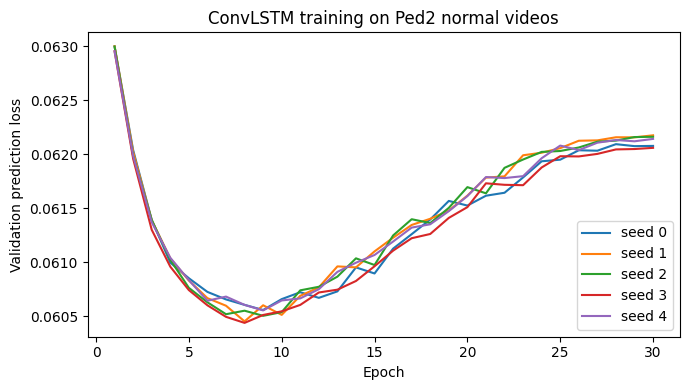

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for seed, history in zip(SEEDS, ped2.histories):
    ax.plot(history["epoch"], history["val_loss"], label=f"seed {seed}")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation prediction loss")
ax.set_title("ConvLSTM training on Ped2 normal videos")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ped2_training_curves.png", dpi=150)
plt.show()

In [10]:
PAIRS = [
    ("ConvLSTM predictor", "Feature difference"),
    ("ConvLSTM predictor", "PatchCore (spatial)"),
    ("Spatial + temporal", "PatchCore (spatial)"),
    ("Spatial + temporal", "ConvLSTM predictor"),
]
ped2_bootstrap = comparison_table(
    ped2.scores["test"], ped2_test, PAIRS, "ped2_bootstrap"
)

,Comparison,Delta AUROC,95% CI low,95% CI high,Share of resamples with no gain
0,ConvLSTM predictor minus Feature difference,0.05731,0.03219,0.07524,0
1,ConvLSTM predictor minus PatchCore (spatial),0.1165,-0.005712,0.3506,0.031
2,Spatial + temporal minus PatchCore (spatial),0.09299,0.01551,0.2232,0.007
3,Spatial + temporal minus ConvLSTM predictor,-0.02349,-0.1491,0.03466,0.726


In [11]:
rows = []
for alpha in np.round(np.linspace(0, 1, 11), 2):
    fused = [
        fuse(t, ped2.scores["test"]["PatchCore (spatial)"][0], r, alpha)
        for t, r in zip(ped2.scores["test"]["ConvLSTM predictor"], ped2.fusion_refs)
    ]
    rows.append(
        summary_row(f"alpha = {alpha}", fused, ped2_test, key="Temporal weight")
    )
alpha_table = present(rows, "ped2_alpha_sensitivity")

rows = []
for method in ["PatchCore (spatial)", "Feature difference", "ConvLSTM predictor"]:
    for fraction in (None, 0.01, 0.05, 0.10):
        sets = []
        for score_set in ped2.scores["test"][method]:
            frame = {}
            for name, maps in score_set.maps.items():
                flat = maps.float().flatten(1)
                frame[name] = (
                    flat.max(dim=1).values
                    if fraction is None
                    else top_fraction_mean(maps.float(), fraction)
                ).numpy()
            sets.append(ScoreSet(frame))
        rows.append(
            {
                **summary_row(method, sets, ped2_test),
                "Aggregation": (
                    "max" if fraction is None else f"top {int(fraction * 100)}%"
                ),
            }
        )
aggregation_table = present(rows, "ped2_aggregation_sensitivity")

,Temporal weight,Runs,AUROC,AUPRC,AUROC per-video min-max
0,alpha = 0.0,5,0.6528 ± 0.0000,0.8940 ± 0.0000,0.6144 ± 0.0000
1,alpha = 0.1,5,0.6734 ± 0.0005,0.9019 ± 0.0002,0.6658 ± 0.0010
2,alpha = 0.2,5,0.6922 ± 0.0009,0.9099 ± 0.0004,0.7101 ± 0.0023
3,alpha = 0.3,5,0.7109 ± 0.0014,0.9178 ± 0.0006,0.7382 ± 0.0060
4,alpha = 0.4,5,0.7294 ± 0.0018,0.9245 ± 0.0007,0.7584 ± 0.0064
5,alpha = 0.5,5,0.7458 ± 0.0019,0.9292 ± 0.0007,0.7687 ± 0.0064
6,alpha = 0.6,5,0.7589 ± 0.0022,0.9314 ± 0.0007,0.7721 ± 0.0066
7,alpha = 0.7,5,0.7684 ± 0.0026,0.9320 ± 0.0008,0.7738 ± 0.0055
8,alpha = 0.8,5,0.7729 ± 0.0027,0.9317 ± 0.0008,0.7735 ± 0.0034
9,alpha = 0.9,5,0.7729 ± 0.0028,0.9306 ± 0.0007,0.7716 ± 0.0032


,Method,Runs,AUROC,AUPRC,AUROC per-video min-max,Aggregation
0,PatchCore (spatial),1,0.6081,0.8669,0.5045,max
1,PatchCore (spatial),1,0.6529,0.8940,0.6144,top 1%
2,PatchCore (spatial),1,0.7406,0.9351,0.7588,top 5%
3,PatchCore (spatial),1,0.7943,0.9531,0.7656,top 10%
4,Feature difference,1,0.6046,0.8662,0.5833,max
5,Feature difference,1,0.7120,0.9090,0.7180,top 1%
6,Feature difference,1,0.7779,0.9392,0.8356,top 5%
7,Feature difference,1,0.7750,0.9405,0.8458,top 10%
8,ConvLSTM predictor,5,0.6646 ± 0.0054,0.8869 ± 0.0016,0.6135 ± 0.0112,max
9,ConvLSTM predictor,5,0.7693 ± 0.0031,0.9288 ± 0.0008,0.7676 ± 0.0030,top 1%


In [12]:
def threshold_table(result, val_videos, test_videos, name):
    rows = []
    for method in METHODS:
        reports = [
            threshold_report(t, v, test_videos, val_videos)
            for v, t in zip(result.scores["val"][method], result.scores["test"][method])
        ]
        averaged = pd.concat(reports).groupby("Percentile", as_index=False).mean()
        averaged.insert(0, "Method", method)
        rows.extend(averaged.to_dict("records"))
    return present(rows, name)


ped2_thresholds = threshold_table(ped2, ped2_val, ped2_test, "ped2_thresholds")

,Method,Percentile,Expected FPR,FPR on normal test frames,TPR on anomalous test frames,False alarm onsets per 1000 normal frames
0,PatchCore (spatial),95,0.05,0.1556,0.2136,9.934
1,PatchCore (spatial),97.5,0.025,0.1225,0.195,6.623
2,PatchCore (spatial),99,0.01,0.1026,0.1835,13.25
3,Feature difference,95,0.05,0.1026,0.2922,72.85
4,Feature difference,97.5,0.025,0.07947,0.2257,62.91
5,Feature difference,99,0.01,0.04305,0.1253,36.42
6,ConvLSTM predictor,95,0.05,0.09669,0.3927,70.2
7,ConvLSTM predictor,97.5,0.025,0.07947,0.3068,59.6
8,ConvLSTM predictor,99,0.01,0.04967,0.2023,38.41
9,Spatial + temporal,95,0.05,0.1331,0.4318,63.58


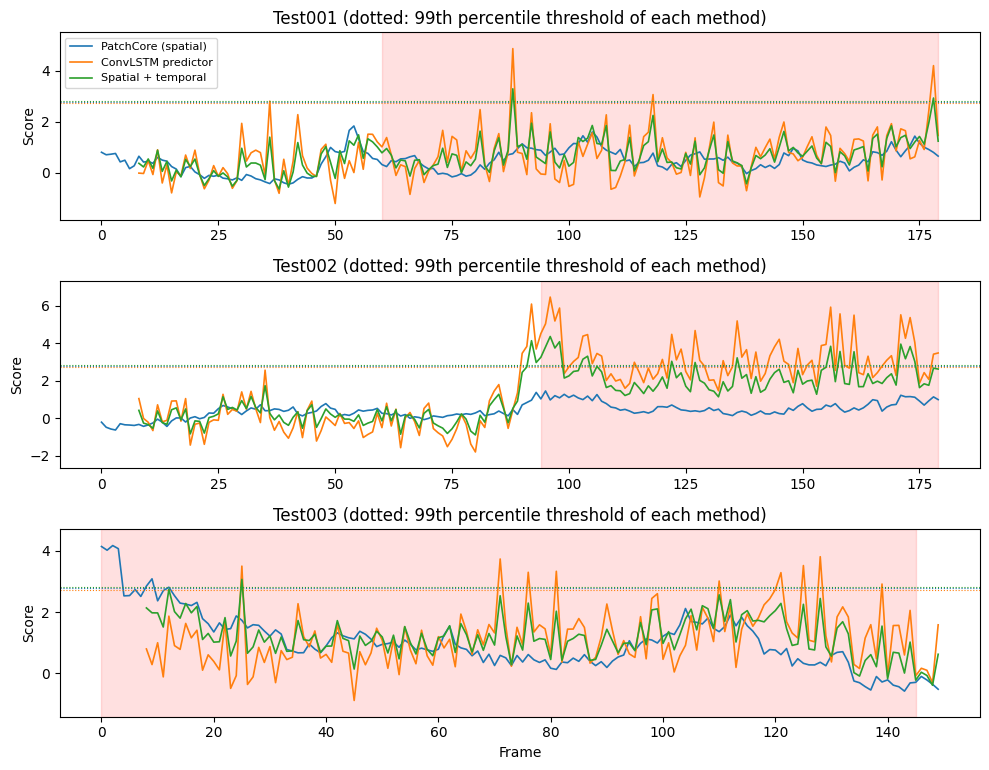

In [13]:
def zscore(values, reference):
    return (values - reference[0]) / reference[1]


shown_videos = ped2_test[:3]
fig, axes = plt.subplots(
    len(shown_videos), 1, figsize=(10, 2.6 * len(shown_videos)), squeeze=False
)
axes = axes[:, 0]
for ax, video in zip(axes, shown_videos):
    for method, colour in [
        ("PatchCore (spatial)", "tab:blue"),
        ("ConvLSTM predictor", "tab:orange"),
        ("Spatial + temporal", "tab:green"),
    ]:
        val_set, test_set = (
            ped2.scores["val"][method][0],
            ped2.scores["test"][method][0],
        )
        reference = frame_reference(val_set, ped2_val)
        threshold = (
            np.percentile(normal_frame_scores(val_set, ped2_val), 99) - reference[0]
        ) / reference[1]
        ax.plot(
            zscore(test_set.frame[video.name], reference),
            color=colour,
            label=method,
            linewidth=1.2,
        )
        ax.axhline(threshold, color=colour, linestyle=":", linewidth=0.8)
    ax.fill_between(
        np.arange(len(video.labels)),
        0,
        1,
        where=video.labels > 0,
        color="red",
        alpha=0.12,
        transform=ax.get_xaxis_transform(),
    )
    ax.set_title(f"{video.name} (dotted: 99th percentile threshold of each method)")
    ax.set_ylabel("Score")
axes[0].legend(loc="upper left", fontsize=8)
axes[-1].set_xlabel("Frame")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ped2_score_timelines.png", dpi=150)
plt.show()

In [14]:
def mean_normal_score(score_sets, videos):
    values = []
    for score_set in score_sets:
        scores, labels = stack_frames(score_set.frame, videos)
        values.append(scores[labels == 0].mean())
    return float(np.mean(values))


ped2_test_bank = FeatureBank(ped2_features, ped2_test, ped2.stats)

variants = {
    "Ordered input": "ordered",
    "Whole sequence shuffled": "full_shuffle",
    "History shuffled, last frame kept": "history_shuffle",
    "History reversed, last frame kept": "history_reversed",
    "Static history, last frame repeated": "static_history",
}
rows = []
for label, mode in variants.items():
    sets = [
        predictor_scores(
            m, ped2_test_bank, CONTEXT_LENGTH, HORIZON, history=mode, seed=i
        )
        for i, m in enumerate(ped2.models)
    ]
    rows.append(
        {
            **summary_row(label, sets, ped2_test, key="Check"),
            "Mean score on normal frames": mean_normal_score(sets, ped2_test),
        }
    )

untrained, random_output = [], []
for seed in SEEDS:
    seed_everything(seed)
    untrained.append(
        predictor_scores(
            FeaturePredictor(zero_init_head=False).to(DEVICE),
            ped2_test_bank,
            CONTEXT_LENGTH,
            HORIZON,
        )
    )
    seed_everything(seed)
    random_output.append(
        predictor_scores(RandomPredictor(), ped2_test_bank, CONTEXT_LENGTH, HORIZON)
    )

for label, sets in [
    ("Untrained ConvLSTM, random head", untrained),
    ("Random output", random_output),
    ("Persistence (feature difference)", ped2.scores["test"]["Feature difference"]),
]:
    rows.append(
        {
            **summary_row(label, sets, ped2_test, key="Check"),
            "Mean score on normal frames": mean_normal_score(sets, ped2_test),
        }
    )
sanity_table = present(rows, "ped2_sanity_checks")

,Check,Runs,AUROC,AUPRC,AUROC per-video min-max,Mean score on normal frames
0,Ordered input,5,0.7693 ± 0.0031,0.9288 ± 0.0008,0.7676 ± 0.0030,0.6916
1,Whole sequence shuffled,5,0.5976 ± 0.0084,0.8902 ± 0.0042,0.5848 ± 0.0114,2.715
2,"History shuffled, last frame kept",5,0.7528 ± 0.0038,0.9246 ± 0.0014,0.7497 ± 0.0045,0.7201
3,"History reversed, last frame kept",5,0.7361 ± 0.0021,0.9200 ± 0.0007,0.7419 ± 0.0071,0.7572
4,"Static history, last frame repeated",5,0.7249 ± 0.0013,0.9156 ± 0.0008,0.7216 ± 0.0083,0.7743
5,"Untrained ConvLSTM, random head",5,0.7119 ± 0.0010,0.9089 ± 0.0003,0.7170 ± 0.0034,0.8167
6,Random output,5,0.5403 ± 0.0056,0.8350 ± 0.0008,0.5145 ± 0.0177,6.566
7,Persistence (feature difference),1,0.7120,0.9090,0.7179,0.8111


In [15]:
ped2_train_bank = FeatureBank(ped2_features, ped2_train, ped2.stats)
ped2_val_bank = FeatureBank(ped2_features, ped2_val, ped2.stats)

configurations = [(k, 1) for k in CONTEXT_ABLATION] + [
    (CONTEXT_LENGTH, h) for h in HORIZON_ABLATION
]
rows, ablation_scores, ablation_pairs = [], {}, []
for context, horizon in configurations:
    if (context, horizon) == (CONTEXT_LENGTH, HORIZON):
        models = ped2.models[: len(ABLATION_SEEDS)]
    else:
        models = [
            train_predictor(
                ped2_train_bank, ped2_val_bank, context, horizon, seed, PED2_EPOCHS
            )[0]
            for seed in ABLATION_SEEDS
        ]
    label = f"{context} frame{'s' if context > 1 else ''} in, {horizon} ahead"
    baseline = f"Persistence, {horizon} ahead"
    ablation_scores[label] = [
        predictor_scores(m, ped2_test_bank, context, horizon) for m in models
    ]
    if baseline not in ablation_scores:
        ablation_scores[baseline] = [
            predictor_scores(PersistencePredictor(), ped2_test_bank, 1, horizon)
        ]
    ablation_pairs.append((label, baseline))
    rows.append(
        {
            **summary_row(
                label, ablation_scores[label], ped2_test, key="Configuration"
            ),
            "Persistence AUROC at same horizon": frame_metrics(
                ablation_scores[baseline][0].frame, ped2_test
            )["AUROC"],
        }
    )
    print(f"done context {context}, horizon {horizon}")
ablation_table = present(rows, "ped2_ablations")
del ped2_train_bank, ped2_val_bank

done context 1, horizon 1
done context 4, horizon 1
done context 8, horizon 1
done context 12, horizon 1
done context 8, horizon 2
done context 8, horizon 4


,Configuration,Runs,AUROC,AUPRC,AUROC per-video min-max,Persistence AUROC at same horizon
0,"1 frame in, 1 ahead",3,0.7612 ± 0.0019,0.9251 ± 0.0005,0.7553 ± 0.0039,0.712
1,"4 frames in, 1 ahead",3,0.7728 ± 0.0034,0.9301 ± 0.0014,0.7716 ± 0.0040,0.712
2,"8 frames in, 1 ahead",3,0.7698 ± 0.0006,0.9288 ± 0.0003,0.7660 ± 0.0010,0.712
3,"12 frames in, 1 ahead",3,0.7711 ± 0.0061,0.9295 ± 0.0024,0.7703 ± 0.0097,0.712
4,"8 frames in, 2 ahead",3,0.8099 ± 0.0011,0.9469 ± 0.0007,0.7954 ± 0.0075,0.7322
5,"8 frames in, 4 ahead",3,0.8326 ± 0.0047,0.9565 ± 0.0013,0.8023 ± 0.0108,0.7732


In [16]:
longest, shortest = f"{max(CONTEXT_ABLATION)} frames in, 1 ahead", "1 frame in, 1 ahead"
context_pairs = ablation_pairs + [
    (longest, shortest),
    (f"{CONTEXT_LENGTH} frames in, 1 ahead", shortest),
]
ablation_bootstrap = comparison_table(
    ablation_scores, ped2_test, context_pairs, "ped2_ablation_bootstrap"
)

,Comparison,Delta AUROC,95% CI low,95% CI high,Share of resamples with no gain
0,"1 frame in, 1 ahead minus Persistence, 1 ahead",0.04924,0.02494,0.06936,0.0025
1,"4 frames in, 1 ahead minus Persistence, 1 ahead",0.06075,0.03762,0.07862,0
2,"8 frames in, 1 ahead minus Persistence, 1 ahead",0.05779,0.03231,0.07592,0
3,"12 frames in, 1 ahead minus Persistence, 1 ahead",0.05911,0.0344,0.07615,0
4,"8 frames in, 2 ahead minus Persistence, 2 ahead",0.07774,0.03885,0.1099,0.0005
5,"8 frames in, 4 ahead minus Persistence, 4 ahead",0.05941,0.01729,0.09979,0.0065
6,"12 frames in, 1 ahead minus 1 frame in, 1 ahead",0.009871,-0.006576,0.02513,0.098
7,"8 frames in, 1 ahead minus 1 frame in, 1 ahead",0.008553,-0.00903,0.02444,0.144


In [17]:
def with_frames(video, frames, labels=None):
    return Video(video.name, frames, video.labels if labels is None else labels)


def warp_frames(frames, matrices):
    height, width = frames.shape[1:3]
    return np.stack(
        [
            cv2.warpAffine(
                f,
                m,
                (width, height),
                flags=cv2.INTER_LINEAR,
                borderMode=cv2.BORDER_REFLECT,
            )
            for f, m in zip(frames, matrices)
        ]
    )


def brightness_contrast(video, rng):
    return with_frames(
        video,
        np.clip(video.frames.astype(np.float32) * 0.65 + 60, 0, 255).astype(np.uint8),
    )


def gaussian_noise(video, rng):
    noisy = (
        video.frames.astype(np.float32)
        + rng.normal(0, 12, video.frames.shape[:3])[..., None]
    )
    return with_frames(video, np.clip(noisy, 0, 255).astype(np.uint8))


def motion_blur(video, rng):
    kernel = np.zeros((9, 9), np.float32)
    kernel[4, :] = 1 / 9
    return with_frames(
        video, np.stack([cv2.filter2D(f, -1, kernel) for f in video.frames])
    )


def gaussian_blur(video, rng):
    return with_frames(
        video, np.stack([cv2.GaussianBlur(f, (0, 0), 2.0) for f in video.frames])
    )


def jpeg_compression(video, rng):
    frames = [
        cv2.imdecode(
            cv2.imencode(".jpg", f, [cv2.IMWRITE_JPEG_QUALITY, 15])[1],
            cv2.IMREAD_UNCHANGED,
        )
        for f in video.frames
    ]
    return with_frames(
        video, np.stack([f if f.ndim == 3 else to_rgb(f) for f in frames])
    )


def viewpoint_shift(video, rng):
    height, width = video.frames.shape[1:3]
    matrix = cv2.getRotationMatrix2D((width / 2, height / 2), 2.0, 1.0)
    matrix[:, 2] += (8, 6)
    return with_frames(video, warp_frames(video.frames, [matrix] * len(video.frames)))


def camera_panning(video, rng):
    height, width = video.frames.shape[1:3]
    phase = rng.uniform(0, 2 * np.pi)
    matrices = []
    for t in range(len(video.frames)):
        matrix = cv2.getRotationMatrix2D(
            (width / 2, height / 2), 1.0 * np.sin(2 * np.pi * t / 60 + phase), 1.0
        )
        matrix[:, 2] += (
            8 * np.sin(2 * np.pi * t / 48 + phase),
            4 * np.sin(2 * np.pi * t / 64 + phase),
        )
        matrices.append(matrix)
    return with_frames(video, warp_frames(video.frames, matrices))


def occlusion(video, rng):
    height, width = video.frames.shape[1:3]
    box_h, box_w = int(0.3 * height), int(0.25 * width)
    top, left = rng.integers(0, height - box_h), rng.integers(0, width - box_w)
    frames = video.frames.copy()
    frames[:, top : top + box_h, left : left + box_w] = 0
    return with_frames(video, frames)


def frame_drop(video, rng):
    return with_frames(video, video.frames[::2], video.labels[::2])


def frame_repeat(video, rng):
    return with_frames(
        video, np.repeat(video.frames, 2, axis=0), np.repeat(video.labels, 2)
    )


CORRUPTIONS = {
    "Brightness and contrast": brightness_contrast,
    "Gaussian noise": gaussian_noise,
    "Motion blur": motion_blur,
    "Gaussian blur": gaussian_blur,
    "JPEG compression": jpeg_compression,
    "Static viewpoint shift": viewpoint_shift,
    "Camera panning": camera_panning,
    "Occlusion": occlusion,
    "Frame drop (2x speed)": frame_drop,
    "Frame repeat (0.5x speed)": frame_repeat,
}


def robustness_rows(
    condition, scores, videos, clean_scores, clean_videos, val_scores, val_videos
):
    rows = []
    for method, sets in scores.items():
        metrics = [frame_metrics(s.frame, videos) for s in sets]
        clean = [
            frame_metrics(s.frame, clean_videos)["AUROC"] for s in clean_scores[method]
        ]
        fpr, tpr = [], []
        for score_set, val_set in zip(sets, val_scores[method]):
            threshold = np.percentile(normal_frame_scores(val_set, val_videos), 99)
            values, labels = stack_frames(score_set.frame, videos)
            fpr.append((values[labels == 0] > threshold).mean())
            tpr.append((values[labels == 1] > threshold).mean())
        aurocs = [m["AUROC"] for m in metrics]
        rows.append(
            {
                "Condition": condition,
                "Method": method,
                "Runs": len(sets),
                "AUROC": np.mean(aurocs),
                "AUROC std": np.std(aurocs),
                "Change in AUROC": np.mean(aurocs) - np.mean(clean),
                "AUPRC": np.mean([m["AUPRC"] for m in metrics]),
                "FPR at P99": np.mean(fpr),
                "TPR at P99": np.mean(tpr),
            }
        )
    return rows


rows = robustness_rows(
    "Clean",
    ped2.scores["test"],
    ped2_test,
    ped2.scores["test"],
    ped2_test,
    ped2.scores["val"],
    ped2_val,
)
shifted_conditions = {}
for index, (condition, corruption) in enumerate(CORRUPTIONS.items()):
    started = time.time()
    rng = np.random.default_rng(index)
    videos = [corruption(v, rng) for v in ped2_test]
    features = extract_features(extractor, videos, PED2_IMAGE_SIZE)
    scores = score_condition(ped2, features, videos)
    rows.extend(
        robustness_rows(
            condition,
            scores,
            videos,
            ped2.scores["test"],
            ped2_test,
            ped2.scores["val"],
            ped2_val,
        )
    )
    if condition in ("Camera panning", "Static viewpoint shift"):
        shifted_conditions[condition] = (videos, scores)
    del features
    print(f"{condition.lower()} done ({time.time() - started:.0f}s)")
robustness_table = present(rows, "ped2_robustness")

brightness and contrast done (39s)
gaussian noise done (46s)
motion blur done (37s)
gaussian blur done (38s)
jpeg compression done (38s)
static viewpoint shift done (38s)
camera panning done (38s)
occlusion done (37s)
frame drop (2x speed) done (18s)
frame repeat (0.5x speed) done (74s)


,Condition,Method,Runs,AUROC,Change in AUROC,AUPRC,FPR at P99,TPR at P99
0,Clean,PatchCore (spatial),1,0.6528,0,0.894,0.1026,0.1835
1,Clean,Feature difference,1,0.7120,0,0.909,0.04305,0.1253
2,Clean,ConvLSTM predictor,5,0.7693 ± 0.0031,0,0.9288,0.04967,0.2023
3,Clean,Spatial + temporal,5,0.7458 ± 0.0019,0,0.9292,0.05298,0.2266
4,Brightness and contrast,PatchCore (spatial),1,0.6855,0.03266,0.902,0.03974,0.1387
5,Brightness and contrast,Feature difference,1,0.7028,-0.009231,0.9063,0.01656,0.01279
6,Brightness and contrast,ConvLSTM predictor,5,0.7635 ± 0.0052,-0.005805,0.9259,0.01854,0.03069
7,Brightness and contrast,Spatial + temporal,5,0.7587 ± 0.0031,0.01291,0.9308,0.01325,0.0399
8,Gaussian noise,PatchCore (spatial),1,0.5884,-0.06446,0.8833,0.09934,0.2065
9,Gaussian noise,Feature difference,1,0.5956,-0.1164,0.8761,0.8841,0.9578


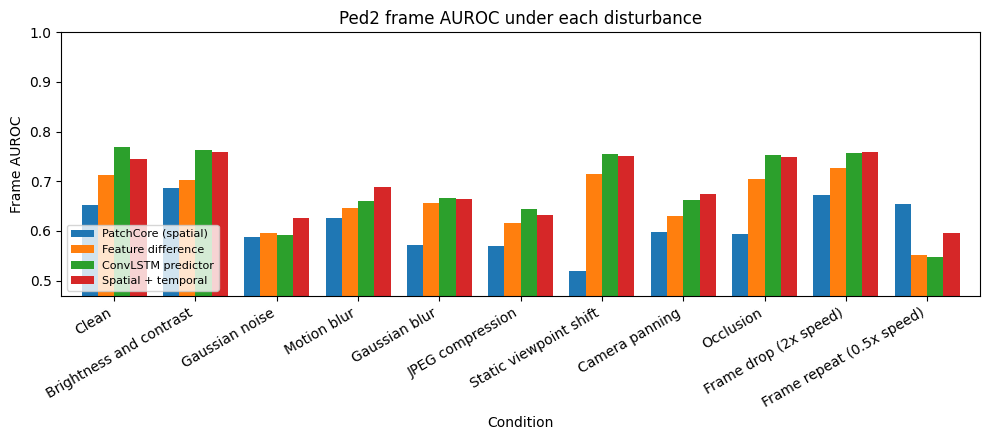

In [18]:
pivot = robustness_table.pivot(index="Condition", columns="Method", values="AUROC").loc[
    ["Clean", *CORRUPTIONS]
]
fig, ax = plt.subplots(figsize=(10, 4.5))
pivot[METHODS].plot.bar(ax=ax, width=0.8)
ax.set_ylabel("Frame AUROC")
ax.set_ylim(max(0.0, pivot.values.min() - 0.05), 1.0)
ax.set_title("Ped2 frame AUROC under each disturbance")
ax.legend(fontsize=8, loc="lower left")
plt.xticks(rotation=30, ha="right")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ped2_robustness.png", dpi=150)
plt.show()

In [19]:
rows = []
for condition, (moved_videos, moved_scores) in shifted_conditions.items():
    for method in METHODS:
        aurocs, moved_flagged, clean_flagged = [], [], []
        for clean_set, moved_set, val_set in zip(
            ped2.scores["test"][method],
            moved_scores[method],
            ped2.scores["val"][method],
        ):
            clean_values, clean_labels = stack_frames(clean_set.frame, ped2_test)
            moved_values, moved_labels = stack_frames(moved_set.frame, moved_videos)
            positives = clean_values[clean_labels == 1]
            negatives = moved_values[moved_labels == 0]
            aurocs.append(
                roc_auc_score(
                    np.r_[np.ones(len(positives)), np.zeros(len(negatives))],
                    np.r_[positives, negatives],
                )
            )
            threshold = np.percentile(normal_frame_scores(val_set, ped2_val), 99)
            moved_flagged.append((negatives > threshold).mean())
            clean_flagged.append((clean_values[clean_labels == 0] > threshold).mean())
        rows.append(
            {
                "Camera motion": condition,
                "Method": method,
                "Runs": len(aurocs),
                "Real anomaly vs moved normal AUROC": np.mean(aurocs),
                "Real anomaly vs moved normal AUROC std": np.std(aurocs),
                "Moved normal frames flagged": np.mean(moved_flagged),
                "Clean normal frames flagged": np.mean(clean_flagged),
            }
        )
camera_table = present(rows, "ped2_camera_motion_test")

,Camera motion,Method,Runs,Real anomaly vs moved normal AUROC,Moved normal frames flagged,Clean normal frames flagged
0,Static viewpoint shift,PatchCore (spatial),1,0.2668,0.02318,0.1026
1,Static viewpoint shift,Feature difference,1,0.8007,0.0298,0.04305
2,Static viewpoint shift,ConvLSTM predictor,5,0.8284 ± 0.0019,0.03444,0.04967
3,Static viewpoint shift,Spatial + temporal,5,0.6507 ± 0.0029,0.04371,0.05298
4,Camera panning,PatchCore (spatial),1,0.5273,0.09934,0.1026
5,Camera panning,Feature difference,1,0.5395,0.1623,0.04305
6,Camera panning,ConvLSTM predictor,5,0.5713 ± 0.0025,0.1894,0.04967
7,Camera panning,Spatial + temporal,5,0.5683 ± 0.0018,0.1649,0.05298


In [20]:
ped2_pixel_masks = prepare_pixel_masks(ped2_test)
rows = []
if ped2_pixel_masks:
    for method in METHODS:
        runs = pd.DataFrame(
            [
                pixel_metrics(s, ped2_test, ped2_pixel_masks)
                for s in ped2.scores["test"][method]
                if s.maps is not None
            ]
        )
        if runs.empty:
            continue
        row = {"Method": method, "Runs": len(runs)}
        for column in runs.columns:
            row[column] = runs[column].mean()
            row[f"{column} std"] = runs[column].std(ddof=0)
        rows.append(row)
    localisation_table = present(rows, "ped2_localisation")
else:
    print("no pixel masks, skipping localisation")

,Method,Runs,Pixel AUROC,AUPRO up to 30% FPR
0,PatchCore (spatial),1,0.9646,0.8448
1,Feature difference,1,0.9674,0.8878
2,ConvLSTM predictor,5,0.9731 ± 0.0001,0.9052 ± 0.0005
3,Spatial + temporal,5,0.9792 ± 0.0001,0.9138 ± 0.0003


In [21]:
def aupro_reference(score_maps, gt_masks, fpr_limit=0.3, steps=1000):
    normal = score_maps[~gt_masks]
    regions = []
    for score_map, mask in zip(score_maps, gt_masks):
        labeled, count = ndimage.label(mask)
        regions += [score_map[labeled == r] for r in range(1, count + 1)]
    thresholds = np.linspace(score_maps.max(), score_maps.min(), steps)
    fprs = np.array([(normal > t).mean() for t in thresholds])
    pros = np.array([np.mean([(r > t).mean() for r in regions]) for t in thresholds])
    keep = fprs <= fpr_limit
    x = np.r_[fprs[keep], fpr_limit]
    y = np.r_[pros[keep], np.interp(fpr_limit, fprs, pros)]
    return area_under(x, y) / fpr_limit



if ped2_pixel_masks:
    check_names = [v.name for v in ped2_test if v.name in ped2_pixel_masks][:2]
    check_set = ped2.scores["test"]["ConvLSTM predictor"][0]
    check_maps = torch.cat(
        [
            upsample_maps(check_set.maps[n][EVAL_START:], PIXEL_EVAL_SIZE)
            for n in check_names
        ]
    )
    check_masks = torch.cat(
        [torch.from_numpy(ped2_pixel_masks[n][EVAL_START:]) for n in check_names]
    )
    flat_scores, flat_labels = check_maps.flatten(), check_masks.flatten()
    
    tied_scores = torch.round(flat_scores * 4) / 4

    rows = []
    for label, values in [
        ("raw maps", flat_scores),
        ("rounded maps (many ties)", tied_scores),
    ]:
        rows.append(
            {
                "Check": f"pixel AUROC, {label}",
                "Fast": fast_auroc(values.to(DEVICE), flat_labels.to(DEVICE)),
                "Reference": roc_auc_score(flat_labels.numpy(), values.numpy()),
            }
        )
    rows.append(
        {
            "Check": "AUPRO up to 30% FPR",
            "Fast": compute_aupro(check_maps.numpy(), check_masks.numpy()),
            "Reference": aupro_reference(check_maps.numpy(), check_masks.numpy()),
        }
    )
    metric_check = pd.DataFrame(rows)
    metric_check["Difference"] = (
        metric_check["Fast"] - metric_check["Reference"]
    ).abs()
    metric_check.to_csv(RESULTS_DIR / "metric_check.csv", index=False)
    display(metric_check)
    print(
        "auroc rows should match to ~1e-6, aupro differs a little since the threshold grids differ"
    )

,Check,Fast,Reference,Difference
0,"pixel AUROC, raw maps",0.9852,0.9852,1.11e-16
1,"pixel AUROC, rounded maps (many ties)",0.9766,0.9766,0
2,AUPRO up to 30% FPR,0.9483,0.9484,8.398e-05


auroc rows should match to ~1e-6, aupro differs a little since the threshold grids differ


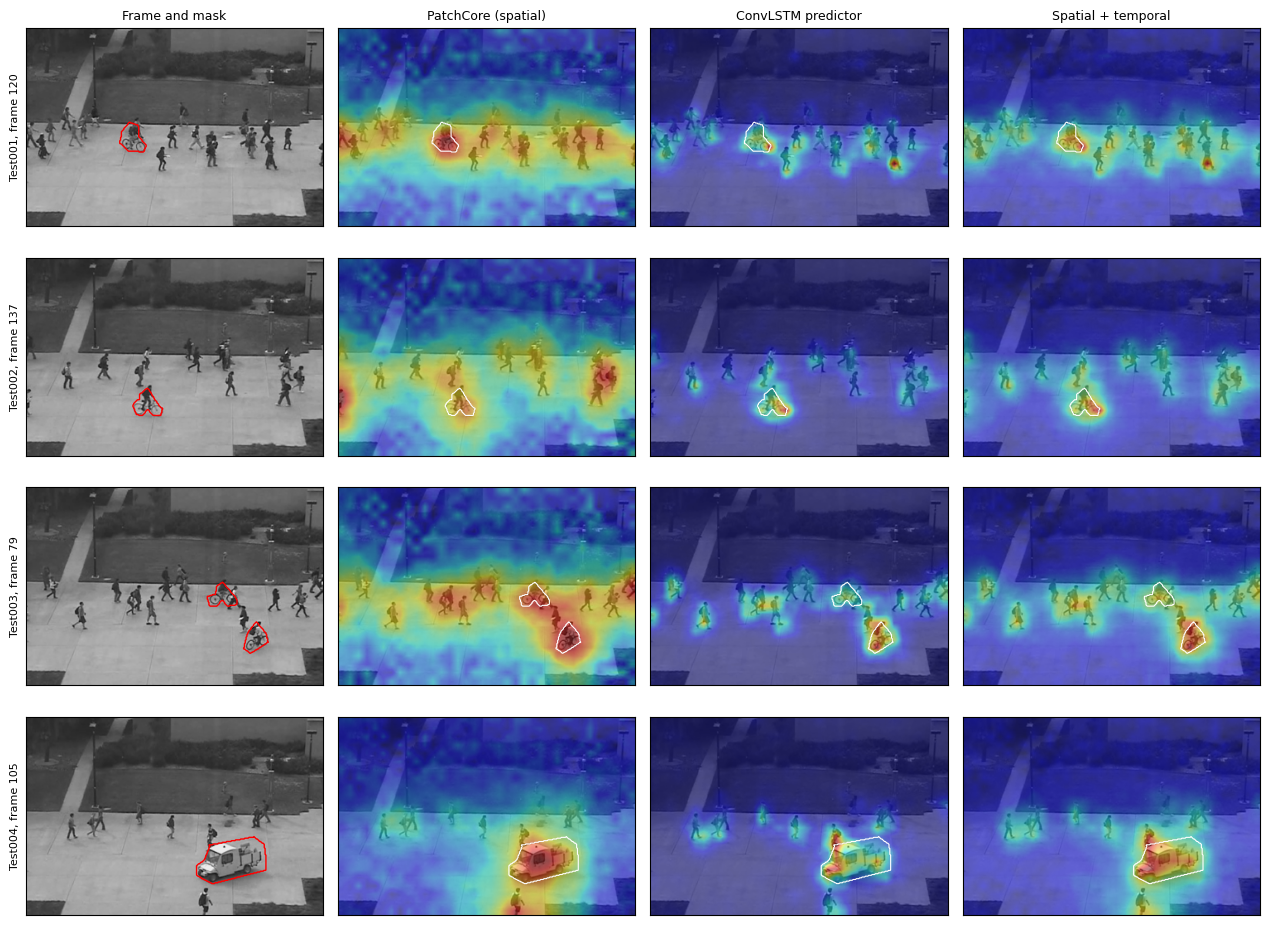

In [22]:
examples = []
for video in ped2_test:
    anomalous = np.flatnonzero(video.labels[EVAL_START:]) + EVAL_START
    if len(anomalous) and video.masks is not None:
        examples.append((video, int(anomalous[len(anomalous) // 2])))
examples = examples[:4]

if examples:
    panels = [
        "Frame and mask",
        "PatchCore (spatial)",
        "ConvLSTM predictor",
        "Spatial + temporal",
    ]
    fig, axes = plt.subplots(
        len(examples),
        len(panels),
        figsize=(3.2 * len(panels), 2.4 * len(examples)),
        squeeze=False,
    )
    for row, (video, index) in enumerate(examples):
        frame = video.frames[index]
        height, width = frame.shape[:2]
        for column, panel in enumerate(panels):
            ax = axes[row, column]
            ax.imshow(frame)
            if panel == "Frame and mask":
                ax.contour(video.masks[index], levels=[0.5], colors="red", linewidths=1)
                ax.set_ylabel(f"{video.name}, frame {index}", fontsize=8)
            else:
                heat = upsample_maps(
                    ped2.scores["test"][panel][0].maps[video.name][index : index + 1],
                    (height, width),
                )[0].numpy()
                ax.imshow(heat, cmap="jet", alpha=0.45)
                ax.contour(
                    video.masks[index], levels=[0.5], colors="white", linewidths=0.8
                )
            if row == 0:
                ax.set_title(panel, fontsize=9)
            ax.set_xticks([])
            ax.set_yticks([])
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "ped2_heatmaps.png", dpi=150)
    plt.show()

In [23]:
def find_dirs(search_root, name):
    return sorted(
        p for p in search_root.rglob(name) if p.is_dir() and "__MACOSX" not in p.parts
    )


def find_avenue(search_root):
    if not search_root.exists():
        return None
    train_dirs = find_dirs(search_root, "training_videos")
    test_dirs = find_dirs(search_root, "testing_videos")
    label_files = sorted(
        f
        for d in find_dirs(search_root, "testing_label_mask")
        for f in d.glob("*_label.mat")
        if not f.name.startswith(".")
    )
    if not (train_dirs and test_dirs and label_files):
        return None
    return train_dirs[0], test_dirs[0], label_files


def locate_avenue():
    paths = find_avenue(INPUT_ROOT) or find_avenue(WORK_DIR / "avenue")
    if paths is not None:
        return paths
    print("avenue not in input, downloading from cuhk site")
    print("its around 2gb so might take a while")
    try:
        for url in AVENUE_URLS:
            fetch_archive(url, WORK_DIR / "avenue")
    except OSError as err:
        print(f"download failed: {err}")
        print("turn on internet or attach avenue manually")
        return None
    return find_avenue(WORK_DIR / "avenue")


def read_video(path, image_size):
    height, width = image_size
    capture = cv2.VideoCapture(str(path))
    frames = []
    while True:
        ok, frame = capture.read()
        if not ok:
            break
        frame = cv2.resize(frame, (width, height), interpolation=cv2.INTER_AREA)
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    capture.release()
    return np.stack(frames)



def read_avenue_labels(path):
    volume = loadmat(str(path))["volLabel"]
    return np.array([np.asarray(mask).any() for mask in volume.ravel()], dtype=np.int64)


def load_avenue(train_dir, test_dir, label_files, image_size):
    label_paths = {int(re.match(r"\d+", p.name).group()): p for p in label_files}

    def avi_files(folder):
        return sorted(p for p in folder.glob("*.avi") if not p.name.startswith("."))

    train = [Video(p.stem, read_video(p, image_size)) for p in avi_files(train_dir)]
    test = []
    for path in avi_files(test_dir):
        frames = read_video(path, image_size)
        labels = read_avenue_labels(label_paths[int(path.stem)])
        if len(frames) != len(labels):
            print(
                f"avenue {path.stem}: {len(frames)} frames but {len(labels)} labels, cutting to the shorter one"
            )
        count = min(len(frames), len(labels))
        test.append(Video(path.stem, frames[:count], labels[:count]))
    return train, test


avenue = None
avenue_paths = locate_avenue() if RUN_AVENUE else None
if avenue_paths is None:
    print("no avenue data, skipping external validation")
else:
    started = time.time()
    avenue_train_all, avenue_test = load_avenue(*avenue_paths, AVENUE_IMAGE_SIZE)
    avenue_train, avenue_val = split_videos(
        avenue_train_all, AVENUE_VALIDATION_VIDEOS, SPLIT_SEED
    )
    avenue_splits = {"train": avenue_train, "val": avenue_val, "test": avenue_test}
    avenue_features = extract_features(
        extractor, avenue_train_all + avenue_test, AVENUE_IMAGE_SIZE
    )
    for video in avenue_train_all + avenue_test:
        video.frames = None  
    print(
        f"avenue: train {len(avenue_train)}, val {len(avenue_val)}, test {len(avenue_test)} videos"
    )
    avenue_test_frames = sum(len(v.labels) for v in avenue_test)
    avenue_anomalous = sum(int(v.labels.sum()) for v in avenue_test)
    print(f"test frames: {avenue_test_frames} ({avenue_anomalous} anomalous)")
    print(f"loaded + cached in {time.time() - started:.0f}s")

    
    avenue = run_pipeline(
        "Avenue",
        avenue_features,
        avenue_splits,
        AVENUE_EPOCHS,
        SEEDS,
        PatchCore(coreset_ratio=0.02, frame_stride=5),
    )
    avenue_main = present(
        [summary_row(m, avenue.scores["test"][m], avenue_test) for m in METHODS],
        "avenue_main_results",
    )
    _, avenue_eval_labels = stack_frames(
        avenue.scores["test"]["PatchCore (spatial)"][0].frame, avenue_test
    )
    print(
        f"anomalous share of scored frames: {avenue_eval_labels.mean():.3f}, a random ranking gets about this auprc"
    )
    avenue_bootstrap = comparison_table(
        avenue.scores["test"], avenue_test, PAIRS, "avenue_bootstrap"
    )
    avenue_thresholds = threshold_table(
        avenue, avenue_val, avenue_test, "avenue_thresholds"
    )

avenue not in input, downloading from cuhk site
its around 2gb so might take a while
avenue: train 13, val 3, test 21 videos
test frames: 15324 (3712 anomalous)
loaded + cached in 74s
patchcore memory: kept 23,973 out of 1,198,656 patches
avenue seed 0: best val loss 0.0319 at epoch 7, 198s
avenue seed 1: best val loss 0.0319 at epoch 7, 196s
avenue seed 2: best val loss 0.0319 at epoch 8, 196s
avenue seed 3: best val loss 0.0319 at epoch 7, 197s
avenue seed 4: best val loss 0.0318 at epoch 7, 197s
val loss if we just copy the last frame: 0.0354


,Method,Runs,AUROC,AUPRC,AUROC per-video min-max
0,PatchCore (spatial),1,0.8253,0.6573,0.8090
1,Feature difference,1,0.7870,0.5914,0.7626
2,ConvLSTM predictor,5,0.8072 ± 0.0003,0.6195 ± 0.0005,0.7535 ± 0.0011
3,Spatial + temporal,5,0.8877 ± 0.0001,0.7208 ± 0.0002,0.8310 ± 0.0009


anomalous share of scored frames: 0.244, a random ranking gets about this auprc


,Comparison,Delta AUROC,95% CI low,95% CI high,Share of resamples with no gain
0,ConvLSTM predictor minus Feature difference,0.02015,0.01043,0.03088,0
1,ConvLSTM predictor minus PatchCore (spatial),-0.01809,-0.1286,0.07471,0.62
2,Spatial + temporal minus PatchCore (spatial),0.06248,0.03236,0.0887,0
3,Spatial + temporal minus ConvLSTM predictor,0.08056,0.007396,0.1667,0.0045


,Method,Percentile,Expected FPR,FPR on normal test frames,TPR on anomalous test frames,False alarm onsets per 1000 normal frames
0,PatchCore (spatial),95,0.05,0,0.05822,0
1,PatchCore (spatial),97.5,0.025,0,0.02911,0
2,PatchCore (spatial),99,0.01,0,0.01034,0
3,Feature difference,95,0.05,0.01299,0.1736,7.108
4,Feature difference,97.5,0.025,0.003071,0.09603,2.106
5,Feature difference,99,0.01,0.0007898,0.02829,0.5265
6,ConvLSTM predictor,95,0.05,0.008213,0.1394,5.3
7,ConvLSTM predictor,97.5,0.025,0.002369,0.06513,1.422
8,ConvLSTM predictor,99,0.01,0.0003159,0.01828,0.3159
9,Spatial + temporal,95,0.05,0.003686,0.07927,1.685


In [24]:
def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def time_call(function, repeats=50, warmup=10):
    for _ in range(warmup):
        function()
    synchronize()
    started = time.perf_counter()
    for _ in range(repeats):
        function()
    synchronize()
    return 1000 * (time.perf_counter() - started) / repeats


height, width = PED2_IMAGE_SIZE
single_frame = torch.from_numpy(
    resize_frames(ped2_test[0].frames[:1], PED2_IMAGE_SIZE)
).to(DEVICE)
with torch.no_grad(), torch.autocast(DEVICE.type, enabled=USE_AMP):
    sample_middle, sample_deep = extractor(single_frame)
sample_embedding = patch_embeddings(sample_middle.float(), sample_deep.float())
sample_queries = sample_embedding.permute(0, 2, 3, 1).reshape(
    -1, sample_embedding.shape[1]
)
predictor = ped2.models[0]


def run_backbone():
    with torch.autocast(DEVICE.type, enabled=USE_AMP):
        extractor(single_frame)


def predictor_runner(context):
    sequence = sample_middle.float().unsqueeze(1).repeat(1, context, 1, 1, 1)

    def run():
        with torch.autocast(DEVICE.type, enabled=USE_AMP):
            predictor(sequence)

    return run


latency_rows = [
    {"Component": "ResNet-18 up to layer 3", "Latency (ms)": time_call(run_backbone)}
]
for context in (4, 8, 12):
    latency_rows.append(
        {
            "Component": f"ConvLSTM, {context} input frames",
            "Latency (ms)": time_call(predictor_runner(context)),
        }
    )
latency_rows.append(
    {
        "Component": "PatchCore nearest-neighbour search",
        "Latency (ms)": time_call(
            lambda: ped2.patchcore.nearest_distance(sample_queries)
        ),
    }
)
latency_table = present(latency_rows, "latency_components")
n_params = sum(p.numel() for p in predictor.parameters())
memory_size, memory_dim = ped2.patchcore.memory.shape
print(f"convlstm params: {n_params:,}")
print(f"patchcore memory: {memory_size:,} x {memory_dim}")

,Component,Latency (ms)
0,ResNet-18 up to layer 3,2.211
1,"ConvLSTM, 4 input frames",2.708
2,"ConvLSTM, 8 input frames",5.011
3,"ConvLSTM, 12 input frames",7.589
4,PatchCore nearest-neighbour search,12.67


convlstm params: 606,912
patchcore memory: 41,472 x 384


In [25]:
@torch.no_grad()
def stream_scores(video, extractor, model, patchcore, stats, reference, image_size):
    mean, std = stats.mean.to(DEVICE), stats.std.to(DEVICE)
    (t_mean, t_std), (s_mean, s_std) = reference.temporal, reference.spatial
    history = deque(maxlen=CONTEXT_LENGTH)
    latencies, scores = [], np.full(len(video.frames), np.nan, dtype=np.float32)
    for index, frame in enumerate(video.frames):
        started = time.perf_counter()
        tensor = torch.from_numpy(resize_frames(frame[None], image_size)).to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=USE_AMP):
            middle, deep = extractor(tensor)
        middle, deep = (
            middle.half().float(),
            deep.half().float(),
        )  
        normalized = ((middle - mean) / std).half()
        embedding = patch_embeddings(middle, deep)
        _, dims, map_h, map_w = embedding.shape
        spatial = top_fraction_mean(
            patchcore.nearest_distance(
                embedding.permute(0, 2, 3, 1).reshape(-1, dims)
            ).view(1, map_h, map_w)
        )
        if len(history) == CONTEXT_LENGTH:
            with torch.autocast(DEVICE.type, enabled=USE_AMP):
                prediction = model(torch.stack(list(history), dim=1))
            temporal = top_fraction_mean(
                (prediction.float() - normalized.float()).pow(2).mean(dim=1)
            )
            scores[index] = (
                FUSION_ALPHA * (temporal - t_mean) / t_std
                + (1 - FUSION_ALPHA) * (spatial - s_mean) / s_std
            ).item()
        history.append(normalized)
        synchronize()
        latencies.append(1000 * (time.perf_counter() - started))
    return scores, latencies


if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
all_latencies, largest_gap = [], 0.0
for video in ped2_test:
    streamed, latencies = stream_scores(
        video,
        extractor,
        ped2.models[0],
        ped2.patchcore,
        ped2.stats,
        ped2.fusion_refs[0],
        PED2_IMAGE_SIZE,
    )
    batch_scores = ped2.scores["test"]["Spatial + temporal"][0].frame[video.name]
    valid = ~np.isnan(streamed)
    largest_gap = max(
        largest_gap, float(np.abs(streamed[valid] - batch_scores[valid]).max())
    )
    
    all_latencies.extend(latencies[CONTEXT_LENGTH:])

all_latencies = np.array(all_latencies)
window = min(500, len(all_latencies) // 2)
streaming = {
    "Frames timed (after warm-up)": len(all_latencies),
    "Median latency (ms)": float(np.median(all_latencies)),
    "95th percentile latency (ms)": float(np.percentile(all_latencies, 95)),
    "Throughput (frames per second)": float(1000 / all_latencies.mean()),
    f"Mean latency, first {window} frames (ms)": float(all_latencies[:window].mean()),
    f"Mean latency, last {window} frames (ms)": float(all_latencies[-window:].mean()),
    "Peak GPU memory (MB)": (
        torch.cuda.max_memory_allocated() / 2**20
        if DEVICE.type == "cuda"
        else float("nan")
    ),
    "Largest gap between streamed and batch fused scores": largest_gap,
}
streaming_table = present([streaming], "streaming_benchmark")
print("last col should be close to 0, small diff is just fp16 rounding (batch 1 vs 64)")

,Frames timed (after warm-up),Median latency (ms),95th percentile latency (ms),Throughput (frames per second),"Mean latency, first 500 frames (ms)","Mean latency, last 500 frames (ms)",Peak GPU memory (MB),Largest gap between streamed and batch fused scores
0,1914,15.41,16.85,64.31,15.34,15.07,884.9,0.003409


last col should be close to 0, small diff is just fp16 rounding (batch 1 vs 64)


In [26]:
try:
    import onnxruntime as ort
except ImportError:
    ort = None

if ort is None:
    print("onnxruntime not installed (internet off?), skipping onnx check")
else:
    cpu_predictor = copy.deepcopy(ped2.models[0]).cpu().float().eval()
    example = torch.randn(1, CONTEXT_LENGTH, *middle_shape)
    onnx_path = RESULTS_DIR / "convlstm_predictor.onnx"
    # only the convlstm predictor is exported, not the full pipeline
    export_options = dict(
        input_names=["history"], output_names=["prediction"], opset_version=17
    )
    # newer torch prints a deprecation warning for the legacy exporter
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            torch.onnx.export(
                cpu_predictor,
                (example,),
                str(onnx_path),
                dynamo=False,
                **export_options
            )
        except TypeError:
            torch.onnx.export(
                cpu_predictor, (example,), str(onnx_path), **export_options
            )

    session = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
    real_history = (
        ped2_test_bank.data[
            ped2_test_bank.offsets[0] : ped2_test_bank.offsets[0] + CONTEXT_LENGTH
        ]
        .float()
        .cpu()
        .unsqueeze(0)
    )
    with torch.no_grad():
        torch_output = cpu_predictor(real_history).numpy()
    onnx_output = session.run(None, {"history": real_history.numpy()})[0]
    feed = {"history": real_history.numpy()}

    def run_torch_cpu():
        cpu_predictor(real_history)

    onnx_summary = {
        "ONNX file size (MB)": onnx_path.stat().st_size / 2**20,
        "Max absolute difference": float(np.abs(torch_output - onnx_output).max()),
        "Mean absolute difference": float(np.abs(torch_output - onnx_output).mean()),
        "PyTorch CPU latency (ms)": time_call(run_torch_cpu, repeats=20, warmup=3),
        "ONNX Runtime CPU latency (ms)": time_call(
            lambda: session.run(None, feed), repeats=20, warmup=3
        ),
    }
    onnx_table = present([onnx_summary], "onnx_parity")

,ONNX file size (MB),Max absolute difference,Mean absolute difference,PyTorch CPU latency (ms),ONNX Runtime CPU latency (ms)
0,3.216,9.537e-07,1.03e-08,48.24,43.3


In [27]:
def mean_auroc(scores, method, videos):
    return float(
        np.mean([frame_metrics(s.frame, videos)["AUROC"] for s in scores[method]])
    )


summary = {
    "ped2": {
        method: mean_auroc(ped2.scores["test"], method, ped2_test) for method in METHODS
    },
    "ped2_bootstrap": ped2_bootstrap.to_dict("records"),
    "settings": {
        "seeds": SEEDS,
        "context_length": CONTEXT_LENGTH,
        "top_fraction": TOP_FRACTION,
        "fusion_alpha": FUSION_ALPHA,
        "ped2_image_size": PED2_IMAGE_SIZE,
        "validation_videos": [v.name for v in ped2_val],
    },
}
if avenue is not None:
    summary["avenue"] = {
        method: mean_auroc(avenue.scores["test"], method, avenue_test)
        for method in METHODS
    }
(RESULTS_DIR / "summary.json").write_text(json.dumps(summary, indent=2, default=float))

print("ped2 mean frame auroc:")
for method, value in summary["ped2"].items():
    print(f"  {method}: {value:.4f}")
if "avenue" in summary:
    print("avenue mean frame auroc:")
    for method, value in summary["avenue"].items():
        print(f"  {method}: {value:.4f}")
print(f"saved tables to {RESULTS_DIR}, figures to {FIGURES_DIR}")

ped2 mean frame auroc:
  PatchCore (spatial): 0.6528
  Feature difference: 0.7120
  ConvLSTM predictor: 0.7693
  Spatial + temporal: 0.7458
avenue mean frame auroc:
  PatchCore (spatial): 0.8253
  Feature difference: 0.7870
  ConvLSTM predictor: 0.8072
  Spatial + temporal: 0.8877
saved tables to /kaggle/working/results, figures to /kaggle/working/figures
